# Disconnected Gaussian tails — S2 prototype

Estimate P(|X|>a), X~N(0,1). Compare direct MC, N(a,1), a balanced two-tail mixture, and a 10% defensive mixture. Ordinary IS uses the full mixture density; it is not self-normalized. See informe.md for prior art and assumptions.

In [1]:
import json, csv
from pathlib import Path
from src.estimators import truth, population_variance
r = json.loads(Path('benchmarks/results.json').read_text())
print('Success gate:', r['success'])
print('RMSE ratio:', r['rmse_ratio'])
for name, row in r['selected'].items():
    print(name, 'mean=', row['mean'], 'relative RMSE=', row['relative_rmse'], 'coverage=', row['coverage_95'])

Success gate: True
RMSE ratio: 0.025446408975887225
direct mean= 5.250000000000001e-05 relative RMSE= 0.6337155869865688 coverage= 0.775
single_tilt mean= 3.15606786497916e-05 relative RMSE= 0.5018070885725991 coverage= 0.0
balanced mean= 6.336006289150364e-05 relative RMSE= 0.016125786000854667 coverage= 0.925
defensive mean= 6.363787412819698e-05 relative RMSE= 0.017356200008867916 coverage= 0.95


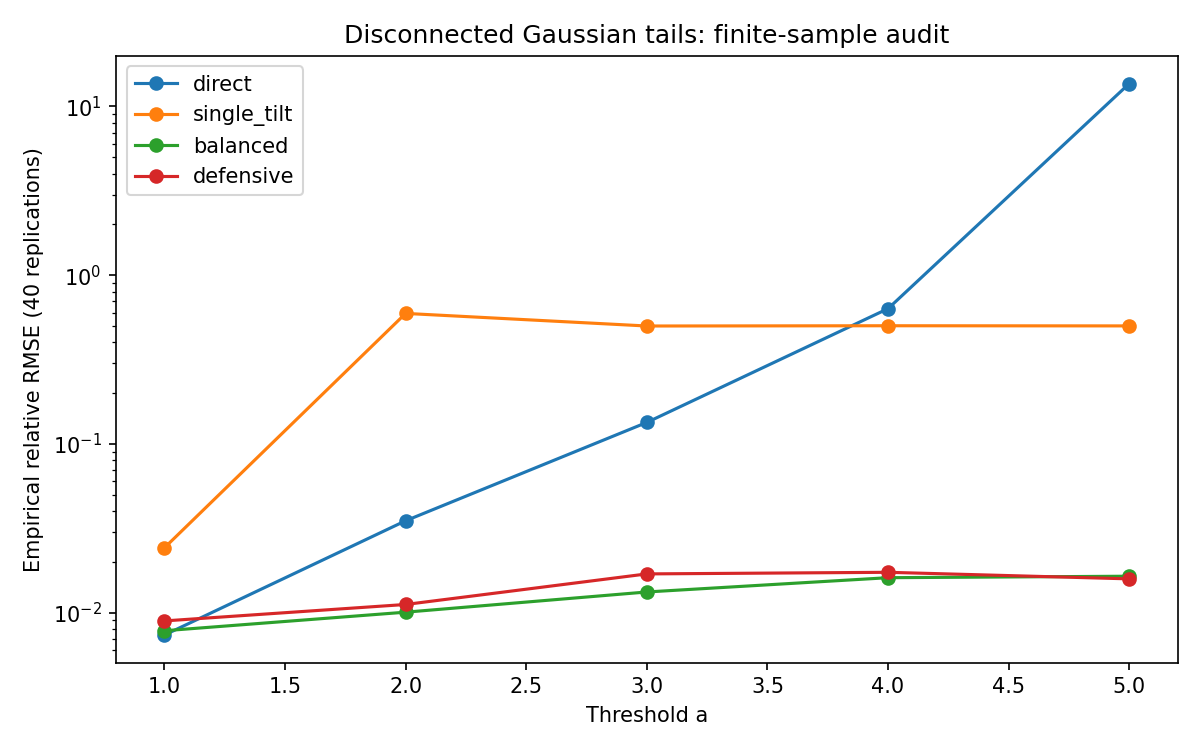

In [2]:
from IPython.display import Image, display
display(Image(filename='benchmarks/rmse.png'))

In [3]:
a=4.0
for m in ['direct','single_tilt','balanced','defensive']:
    print(m, 'true per-draw variance:', population_variance(a,m))
print('Exact event probability:', truth(a))

direct true per-draw variance: 6.333847139600271e-05
single_tilt true per-draw variance: 4443055.260253938
balanced true per-draw variance: 1.8099787045672554e-08
defensive true per-draw variance: 2.0555451246772345e-08
Exact event probability: 6.334248366623973e-05


## Conclusions
A proposal shifted to one tail remains unbiased in expectation but misses the other tail in finite samples and can report misleadingly small standard errors. The balanced mixture is a known remedy, not a new algorithm. Forty replications do not establish coverage calibration. This univariate synthetic experiment does not validate financial capital estimates or high-dimensional performance.

## Desarrollo semanal: mecanismo, sensibilidad y controles

Las celdas nuevas recalculan experimentos específicos. Las salidas históricas anteriores se conservan como evidencia separada y no sustituyen esta ejecución.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
SEED=20261018


### Segundo momento y presupuesto de simulación
Para IS ordinario, $\hat p=N^{-1}\sum 1_E(X_i)p(X_i)/q(X_i)$ y $Var(\hat p)=Var_q(1_Ep/q)/N$. La densidad q debe cubrir las dos colas; usar sólo el componente que generó una observación no es el peso de una mezcla.

Se contrasta RMSE entre 60 réplicas con desviación estándar teórica. Un RMSE empírico pequeño con tilt de una cola puede esconder una segunda cola nunca observada y un segundo momento enorme.

In [5]:
from src.estimators import estimate,truth,population_variance
records=[];N=4000
for a in [2.,3.,4.,5.]:
    reference=truth(a)
    for method in ['direct','single_tilt','balanced','defensive']:
        theoretical=np.sqrt(population_variance(a,method)/N)
        for replicate in range(60):
            result=estimate(a,N,SEED+replicate,method)
            records.append(dict(a=a,method=method,replicate=replicate,estimate=result.mean,
                squared_relative_error=((result.mean-reference)/reference)**2,
                zero=result.mean==0,left_hits=result.left_hits,right_hits=result.right_hits,
                reported_se=result.se,covered=abs(result.mean-reference)<=1.96*result.se,
                theoretical_relative_sd=theoretical/reference))
raw_new=pd.DataFrame(records)
rare_summary=raw_new.groupby(['a','method']).agg(relative_rmse=('squared_relative_error',lambda s:np.sqrt(s.mean())),
    zero_fraction=('zero','mean'),coverage_normal_approx=('covered','mean'),min_left_hits=('left_hits','min'),
    theoretical_relative_sd=('theoretical_relative_sd','first')).reset_index()
display(rare_summary.round(5))
assert len(raw_new)==4*4*60 and np.isfinite(rare_summary.theoretical_relative_sd).all()

,a,method,relative_rmse,zero_fraction,coverage_normal_approx,min_left_hits,theoretical_relative_sd
0,2.0,balanced,0.02458,0.00000,0.95000,941,2.419000e-02
1,2.0,defensive,0.02589,0.00000,0.93333,858,2.567000e-02
2,2.0,direct,0.07358,0.00000,0.91667,72,7.242000e-02
3,2.0,single_tilt,2.36193,0.00000,0.13333,0,1.815630e+00
4,3.0,balanced,0.03046,0.00000,0.93333,941,2.910000e-02
5,3.0,defensive,0.03136,0.00000,0.93333,851,3.109000e-02
6,3.0,direct,0.36426,0.00000,0.95000,0,3.038900e-01
7,3.0,single_tilt,0.50080,0.00000,0.00000,0,3.727771e+02
8,4.0,balanced,0.03570,0.00000,0.91667,941,3.358000e-02
9,4.0,defensive,0.03708,0.00000,0.93333,851,3.579000e-02


### Comparar teoría con experiencia finita
Las escalas logarítmicas permiten ver la divergencia entre la varianza teórica del tilt unilateral y su aparente estabilidad entre sólo 60 realizaciones. Los intervalos normales de rare events pueden degenerar en [0,0] cuando no hay impactos.

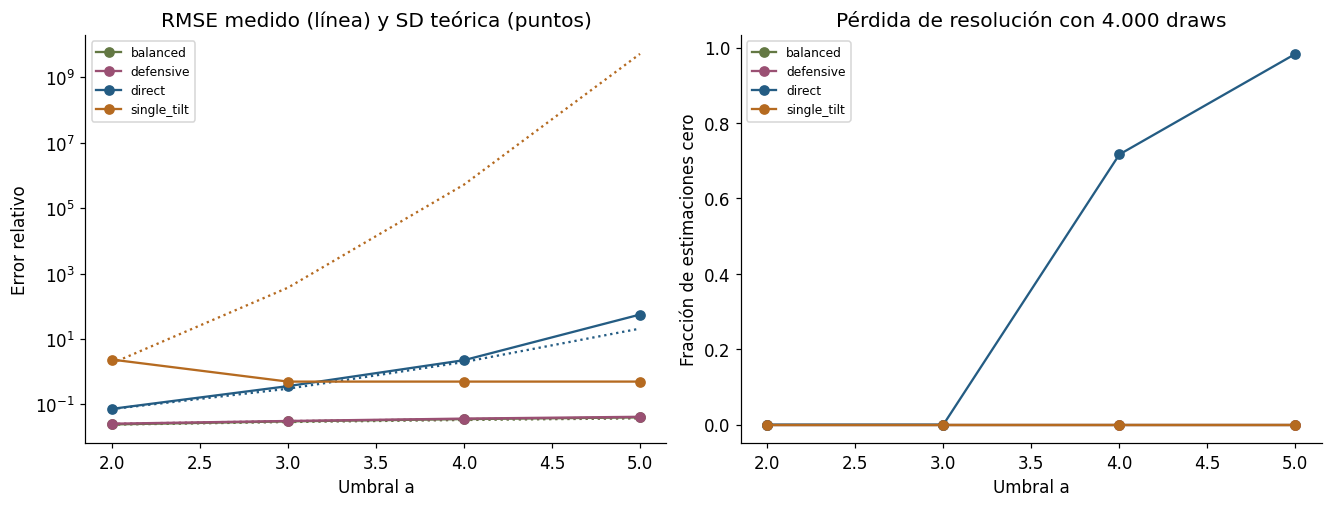

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
colors={'direct':'#245C83','single_tilt':'#B56A20','balanced':'#637843','defensive':'#9A5073'}
for method,group in rare_summary.groupby('method'):
    axes[0].semilogy(group.a,group.relative_rmse,'o-',color=colors[method],label=method)
    axes[0].semilogy(group.a,group.theoretical_relative_sd,':',color=colors[method])
    axes[1].plot(group.a,group.zero_fraction,'o-',color=colors[method],label=method)
axes[0].set(xlabel='Umbral a',ylabel='Error relativo',title='RMSE medido (línea) y SD teórica (puntos)')
axes[1].set(xlabel='Umbral a',ylabel='Fracción de estimaciones cero',title='Pérdida de resolución con 4.000 draws')
for ax in axes:ax.legend(fontsize=8)
plt.show()

### Comprobación independiente de soporte
La probabilidad real se contrasta con la función de supervivencia normal de SciPy. La identidad del segundo momento no demuestra que 60 réplicas lo estimen con precisión: precisamente, el control unilateral muestra el fallo de ese supuesto.

In [7]:
from scipy.stats import norm
for a in [2.,3.,4.,5.]:
    assert abs(truth(a)-2*norm.sf(a))<1e-14
selected=rare_summary.query('a==5')
display(selected[['method','relative_rmse','theoretical_relative_sd','zero_fraction','coverage_normal_approx']])
print('Cobertura mostrada: aproximación normal, 60 réplicas, sin certificación de calibración.')

Cobertura mostrada: aproximación normal, 60 réplicas, sin certificación de calibración.


,method,relative_rmse,theoretical_relative_sd,zero_fraction,coverage_normal_approx
12,balanced,0.040324,3.767388e-02,0.000000,0.916667
13,defensive,0.042126,4.005996e-02,0.000000,0.916667
14,direct,56.175980,2.088227e+01,0.983333,0.016667
15,single_tilt,0.501452,5.233012e+09,0.000000,0.000000


### Límite de aplicación
Los resultados son de una normal univariada y un evento de dos colas conocido. No permiten validar automáticamente importancia en alta dimensión ni riesgo financiero extremo. Con propuestas adaptativas debe separarse entrenamiento de evaluación; aquí las propuestas están prefijadas.